# Hierarchical Risk Parity Extension

This notebook evaluates Hierarchical Risk Parity (HRP) as a modern allocation extension for the 23-ETF core universe.

## Estimation error

Classical mean-variance portfolios depend on estimated expected returns and covariances. Small input changes can produce large allocation changes, especially when assets are highly correlated or the estimation window is short relative to the number of assets.

## Why covariance inversion is unstable

Maximum-Sharpe and related analytical solutions rely directly or indirectly on covariance inversion. When the covariance matrix is ill-conditioned, estimation noise is magnified and the resulting portfolio can become concentrated and unstable. Shrinkage helps, but it does not eliminate expected-return uncertainty or the sensitivity of matrix inversion.

## Hierarchical clustering intuition

HRP converts correlations into distances, clusters similar ETFs, orders them through the hierarchy, and allocates risk recursively across cluster branches. The method uses the dependency structure of the assets without directly inverting the covariance matrix. PyPortfolioOpt's `HRPOpt` implementation is applied to each trailing 60-month return window.

## Why HRP may improve robustness

By allocating across clusters rather than optimizing a noisy return-to-risk ratio, HRP may reduce concentration and sensitivity to estimation error. Robustness is evaluated out of sample using weights estimated through t-1, next-month realized returns, drift-aware turnover, and the same 5 basis-point transaction cost as the other optimized strategies.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

PROJECT_ROOT = Path.cwd().resolve().parent if Path.cwd().name == 'notebooks' else Path.cwd().resolve()
hrp_summary = pd.read_csv(PROJECT_ROOT / 'outputs/tables/hrp_return_summary.csv')
final_comparison = pd.read_csv(PROJECT_ROOT / 'outputs/tables/final_strategy_comparison.csv')
hrp_summary

  strategy covariance_method  start_date    end_date  n_months  annualized_geometric_return  annualized_volatility  sharpe_ratio  sortino_ratio  max_drawdown  calmar_ratio  annualized_turnover  average_effective_number_of_assets  average_herfindahl_index  final_wealth
0      HRP      hierarchical  2013-03-31  2026-05-31       159                     0.016228                0.00578     -0.670415      -0.911722     -0.003482       4.66113             0.074864                            1.094479                  0.917182       1.23775

In [2]:
final_comparison.sort_values('sharpe_ratio', ascending=False)

                         strategy covariance_method  annualized_geometric_return  annualized_volatility  sharpe_ratio  sortino_ratio  max_drawdown  calmar_ratio  annualized_turnover  average_effective_number_of_assets  average_herfindahl_index  final_wealth
5          Max Sharpe Ledoit-Wolf       ledoit_wolf                     0.098585               0.084506      0.922408       1.443033     -0.220241      0.447620             0.880606                            4.766074                  0.212585      3.475710
4               Max Sharpe Sample            sample                     0.092280               0.078862      0.909045       1.423982     -0.206550      0.446766             0.991433                            4.495305                  0.223571      3.220503
8                     Michaud 100       ledoit_wolf                     0.092338               0.079545      0.902569       1.417119     -0.204850      0.450761             0.915265                            6.233824         

## Interpretation of the HRP allocation

Unconstrained HRP can collapse into a defensive low-volatility ETF when a cash-like asset is included in the universe. Here, BIL's exceptionally low variance caused the recursive risk allocation to place nearly all portfolio weight in BIL. The resulting portfolio has very low turnover and drawdown, but weak excess performance and little effective diversification. HRP's cash concentration is an empirical property of unconstrained hierarchical allocation in a universe containing a near-zero-volatility cash proxy. Constrained HRP, HRP without cash, and minimum asset-class allocations are natural robustness checks.


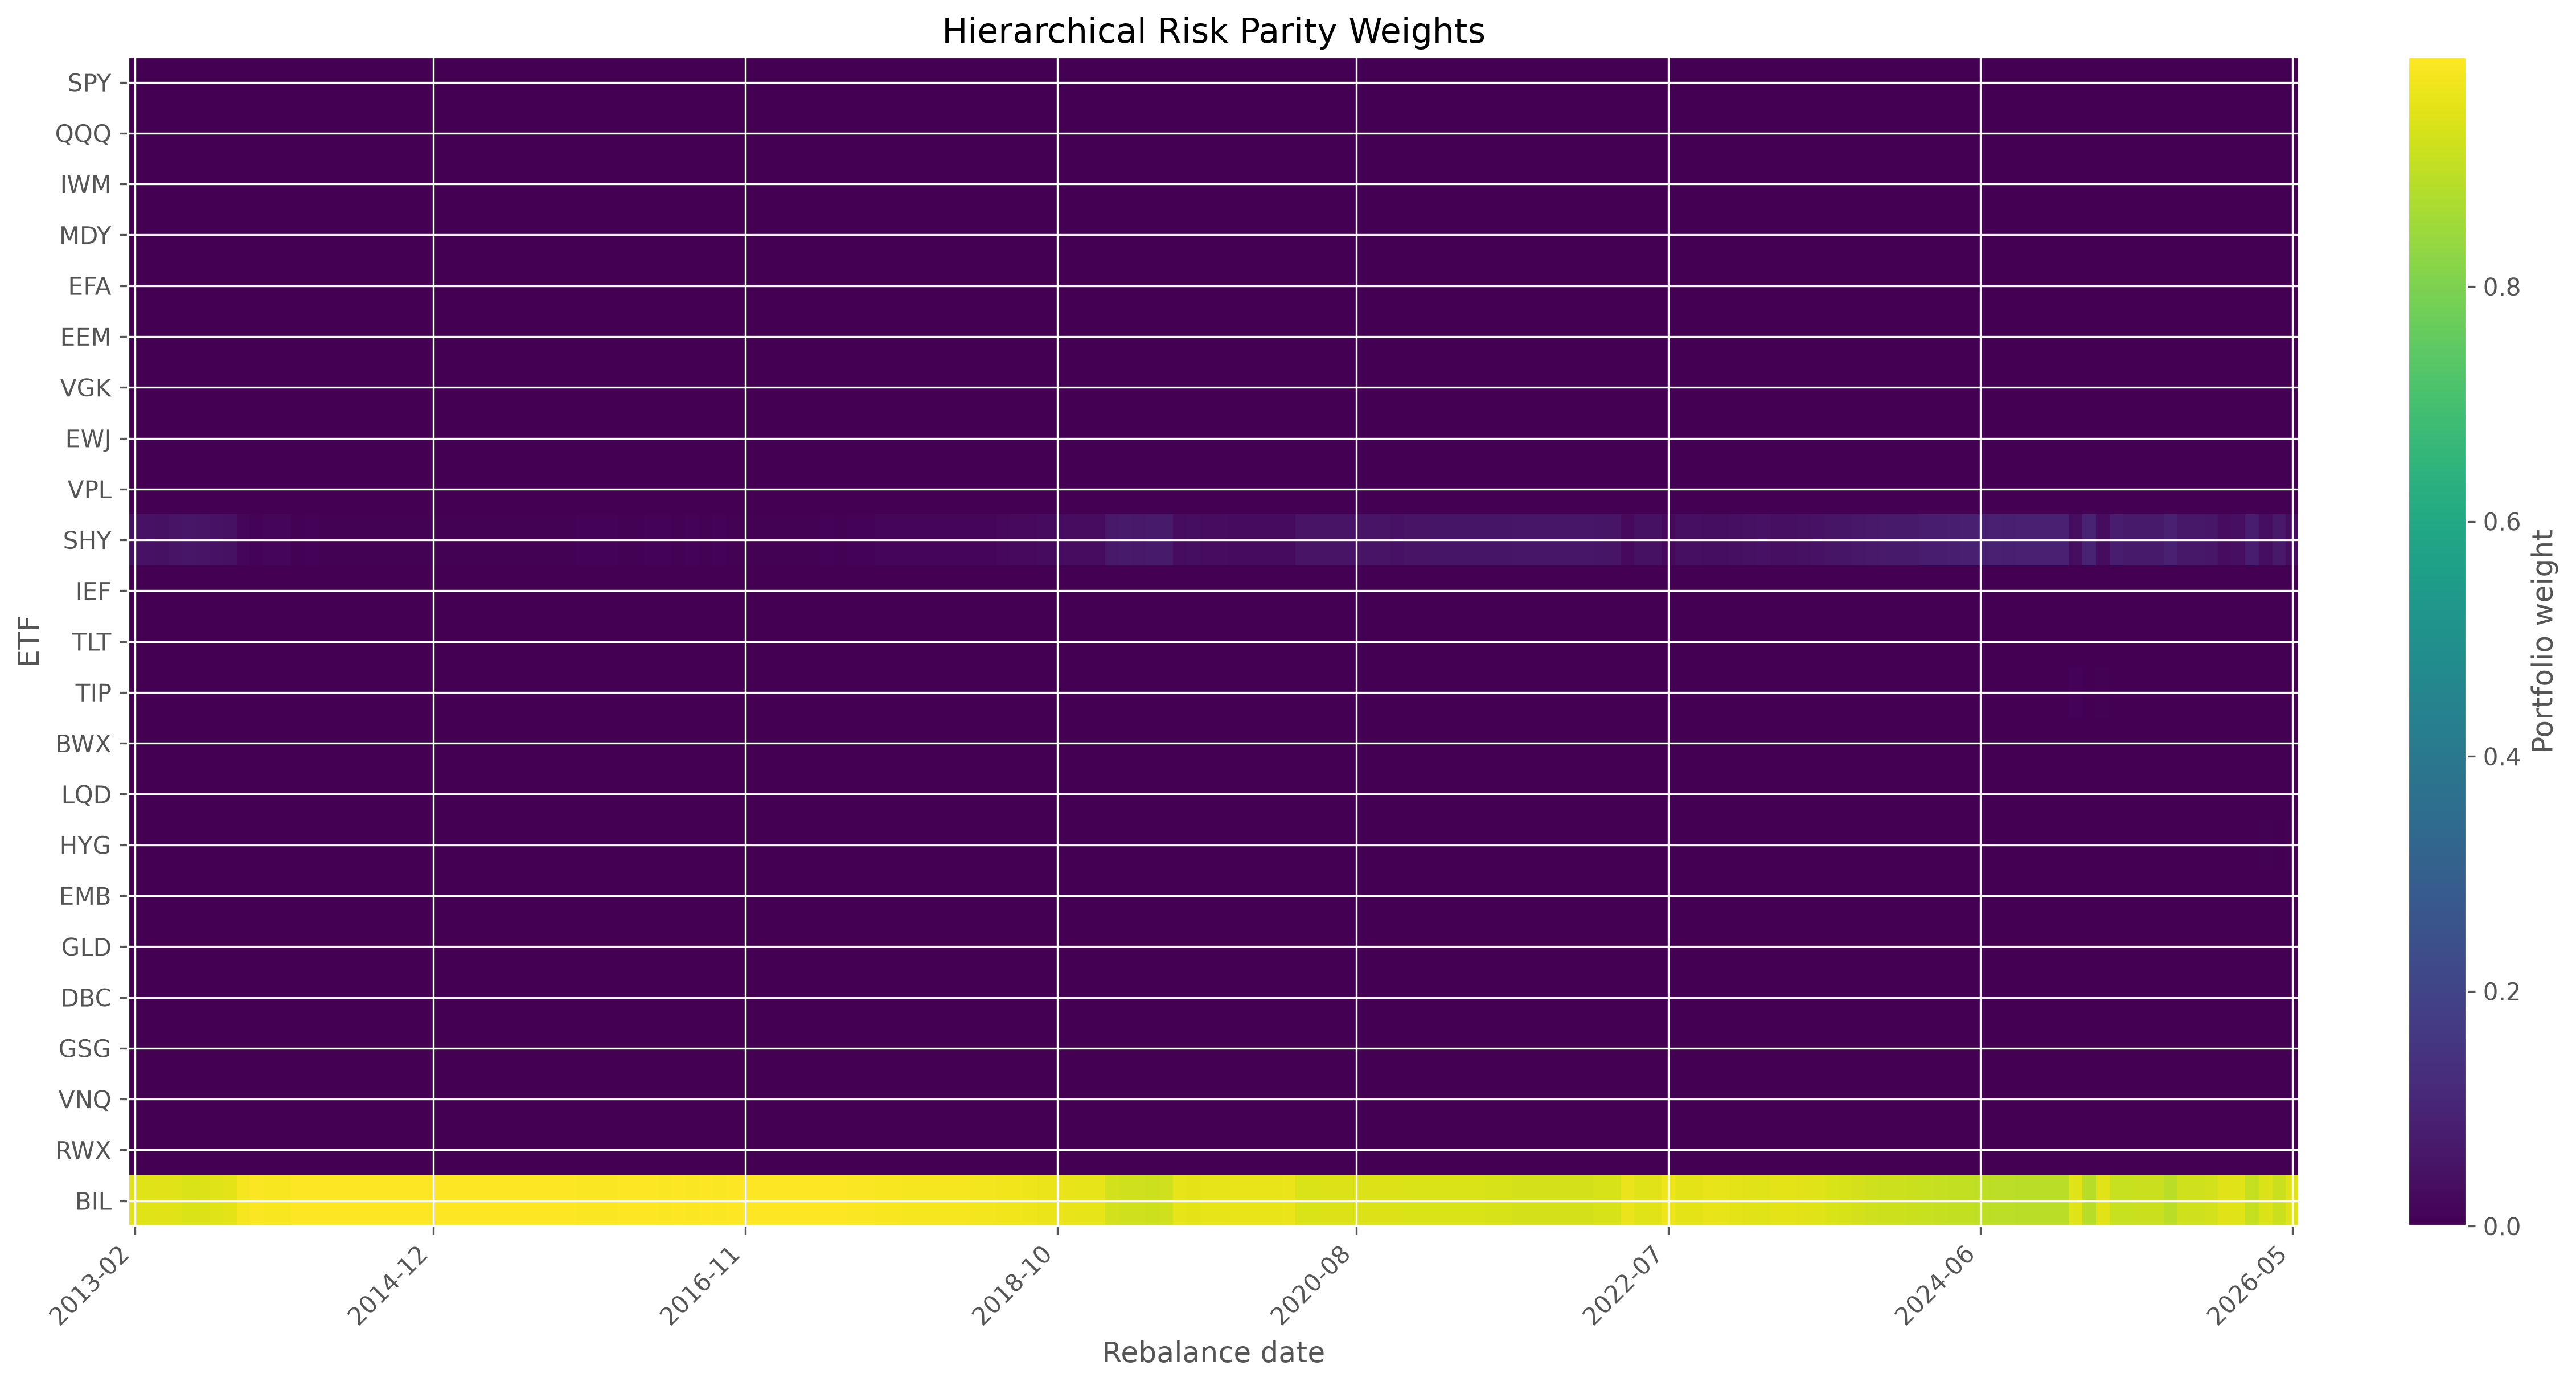

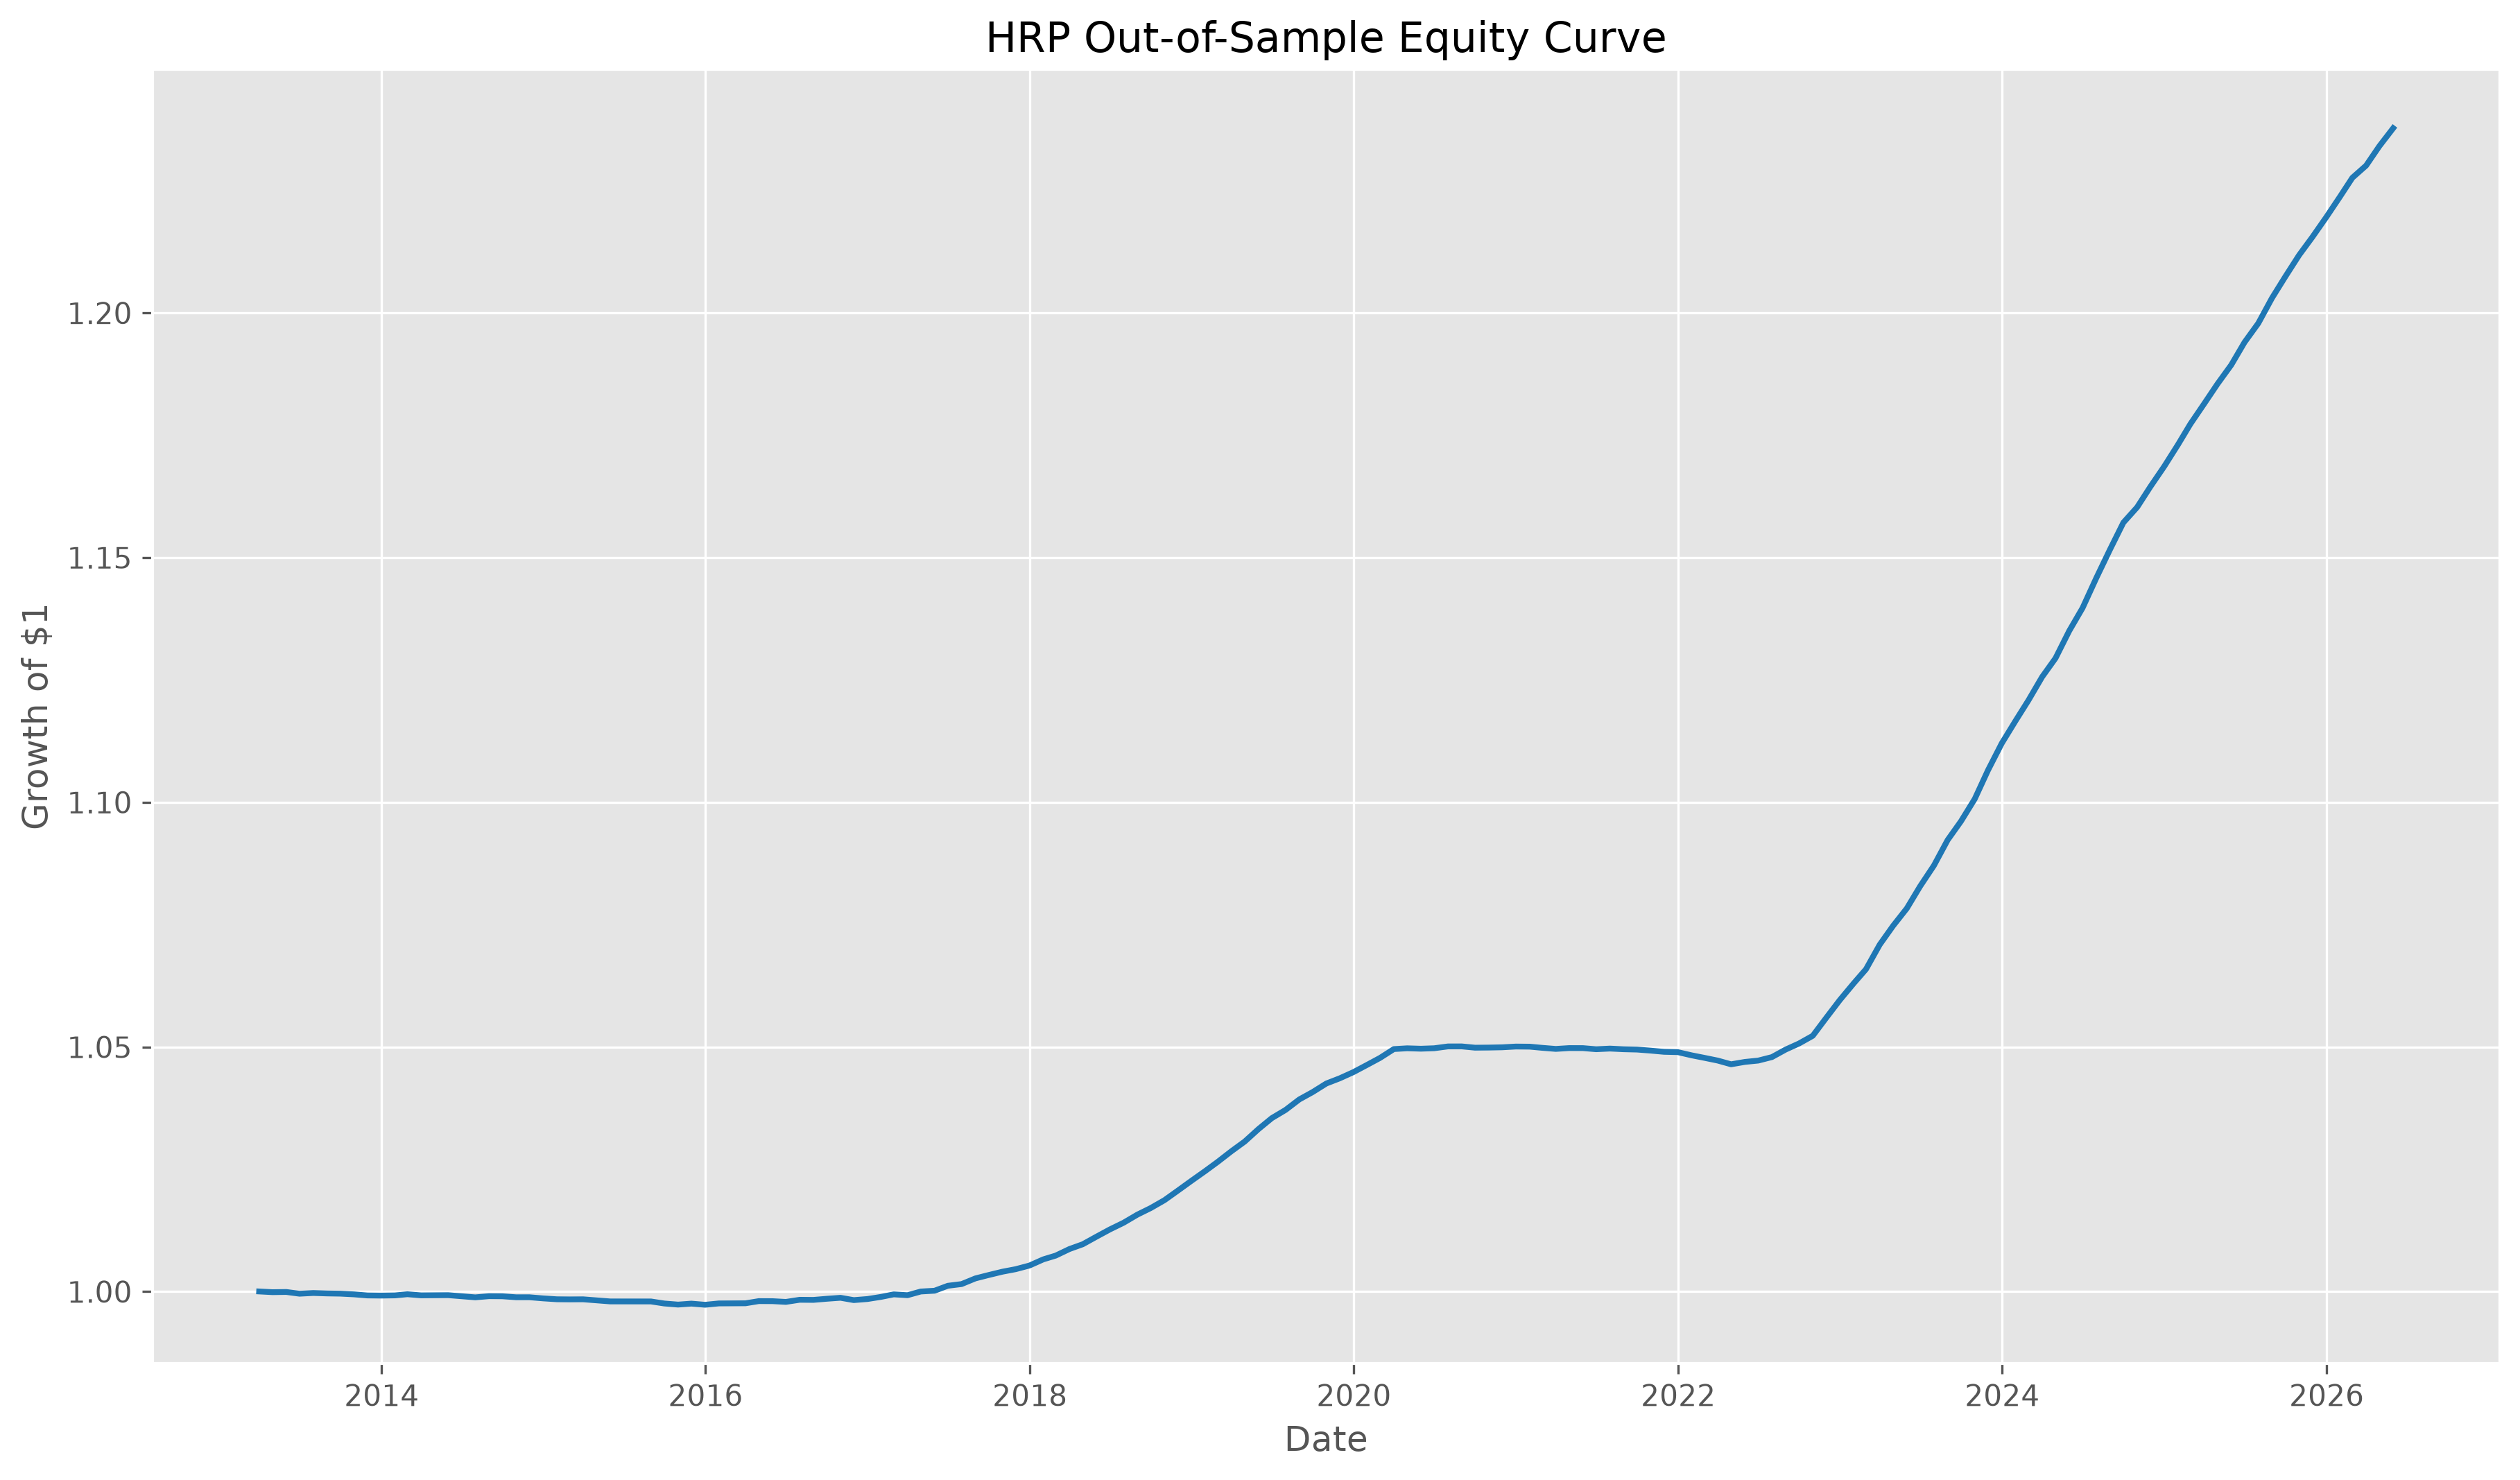

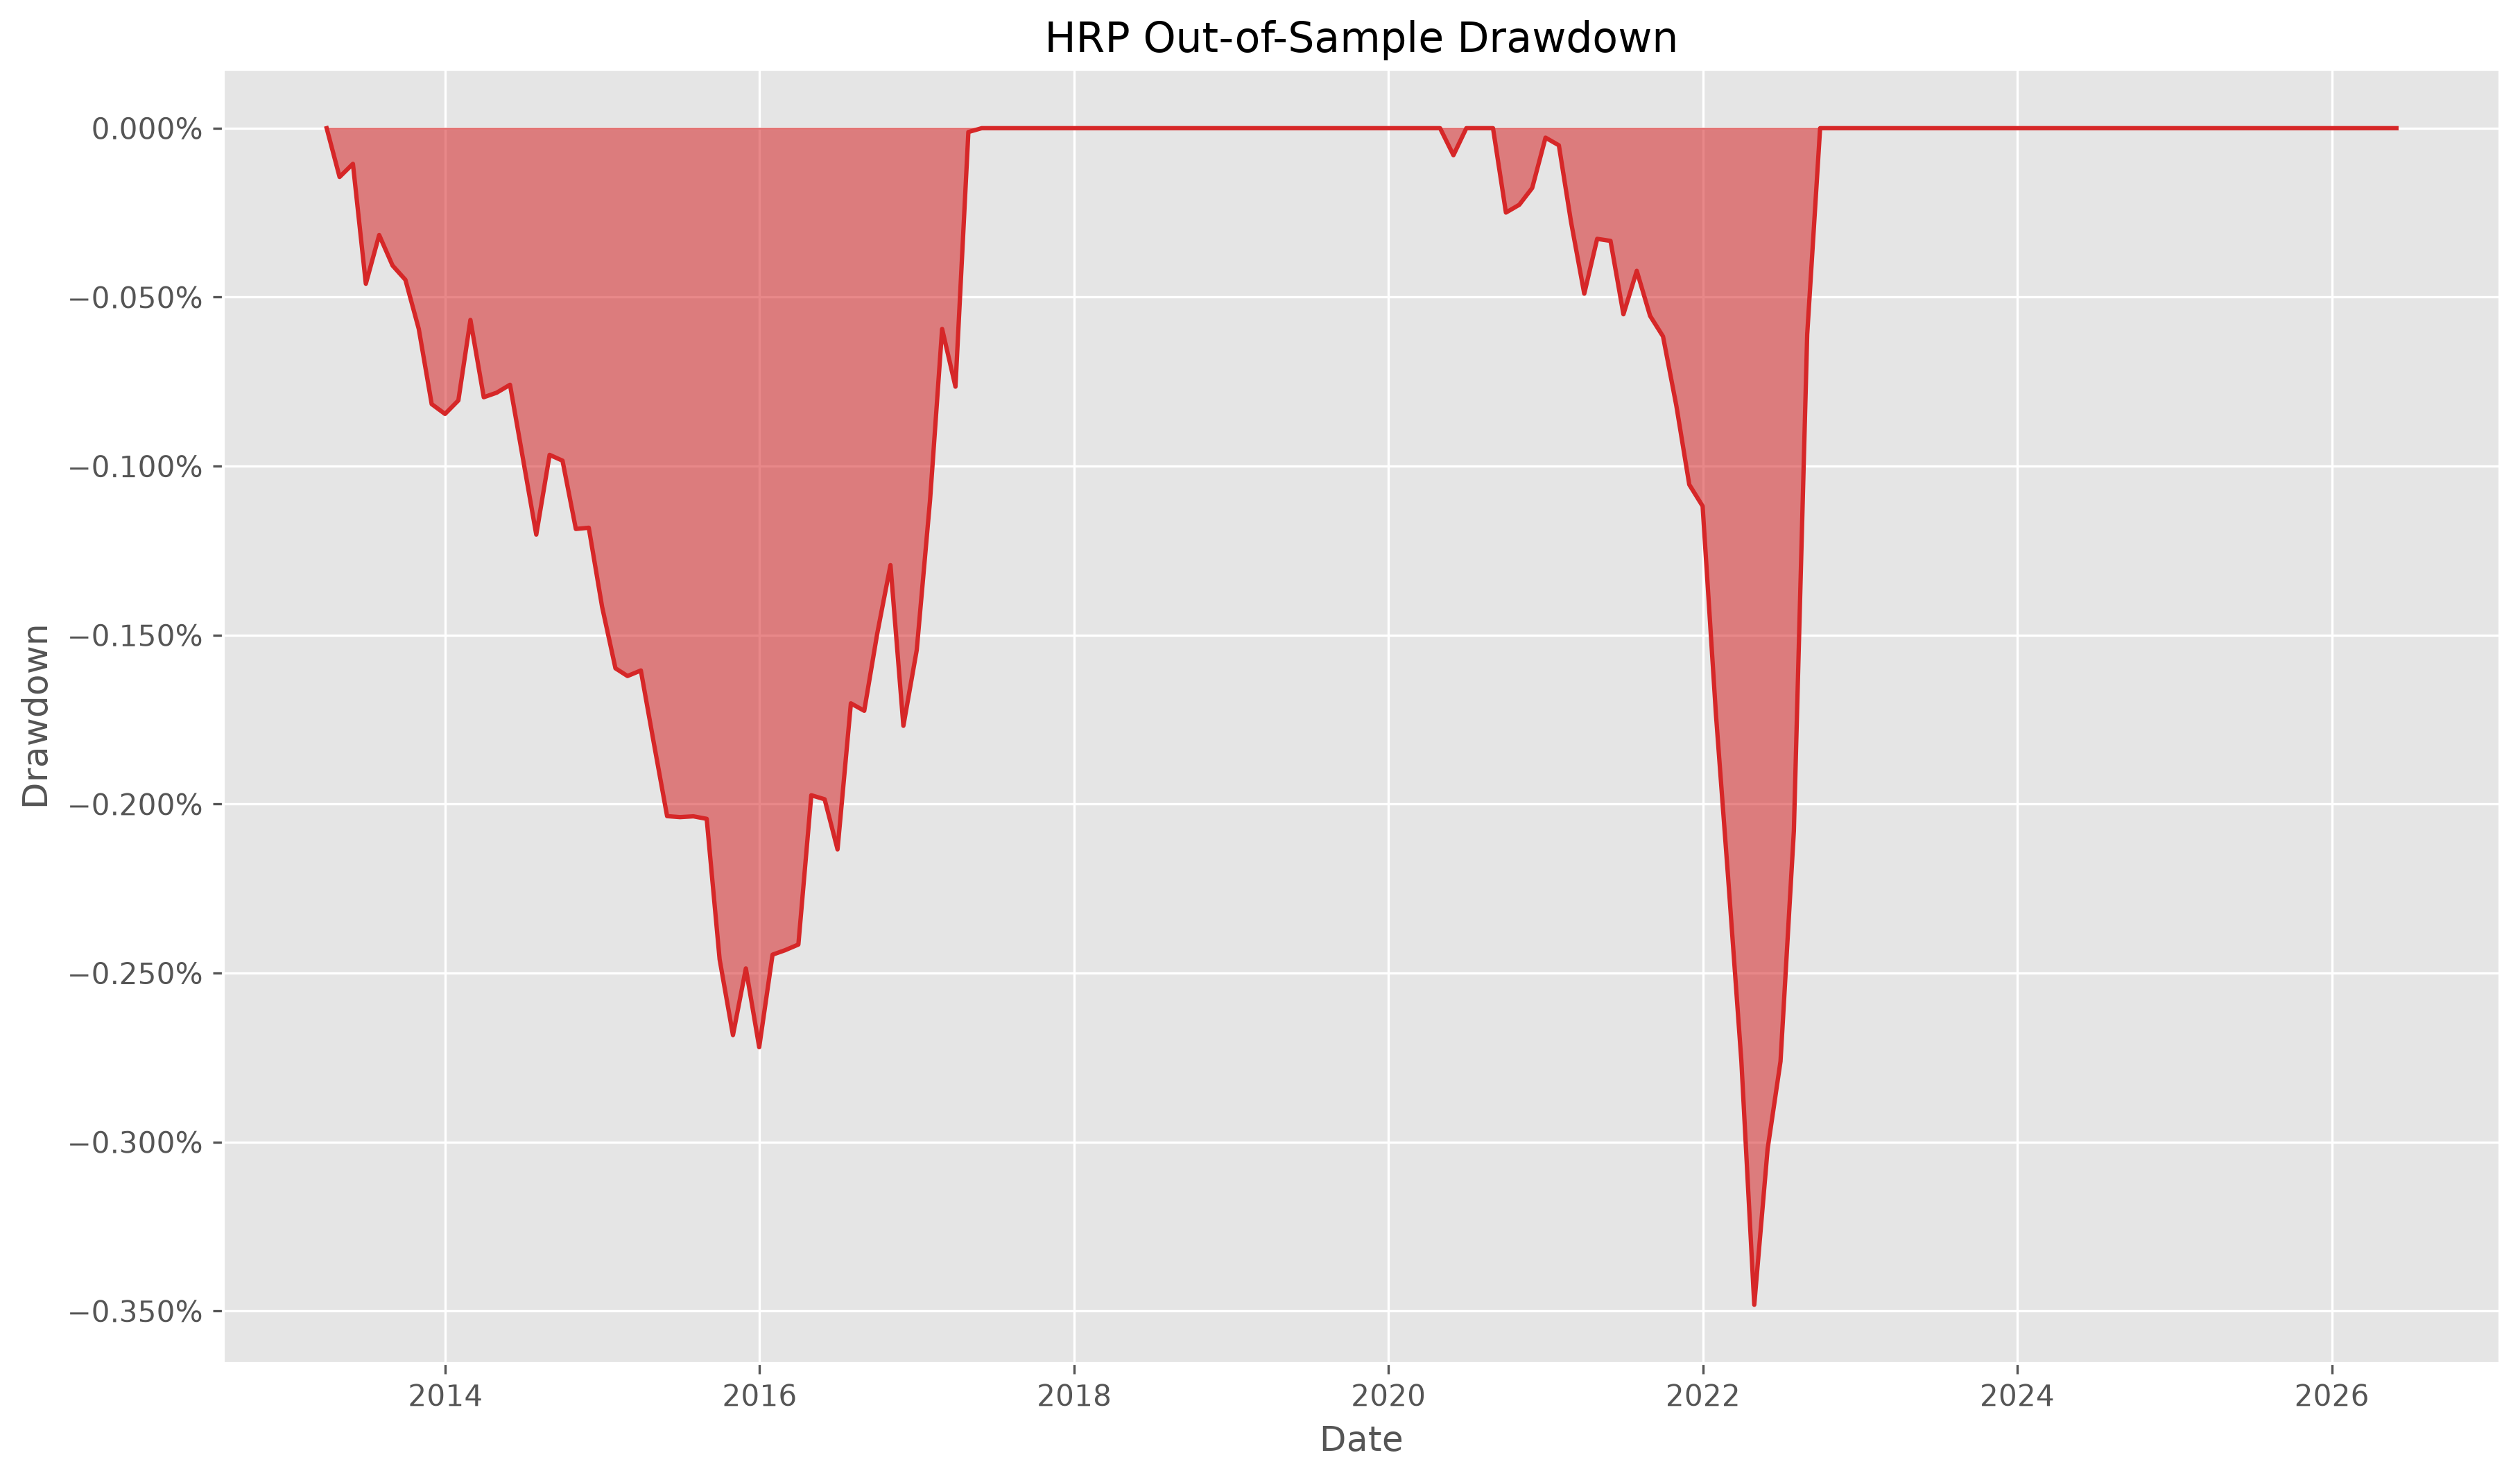

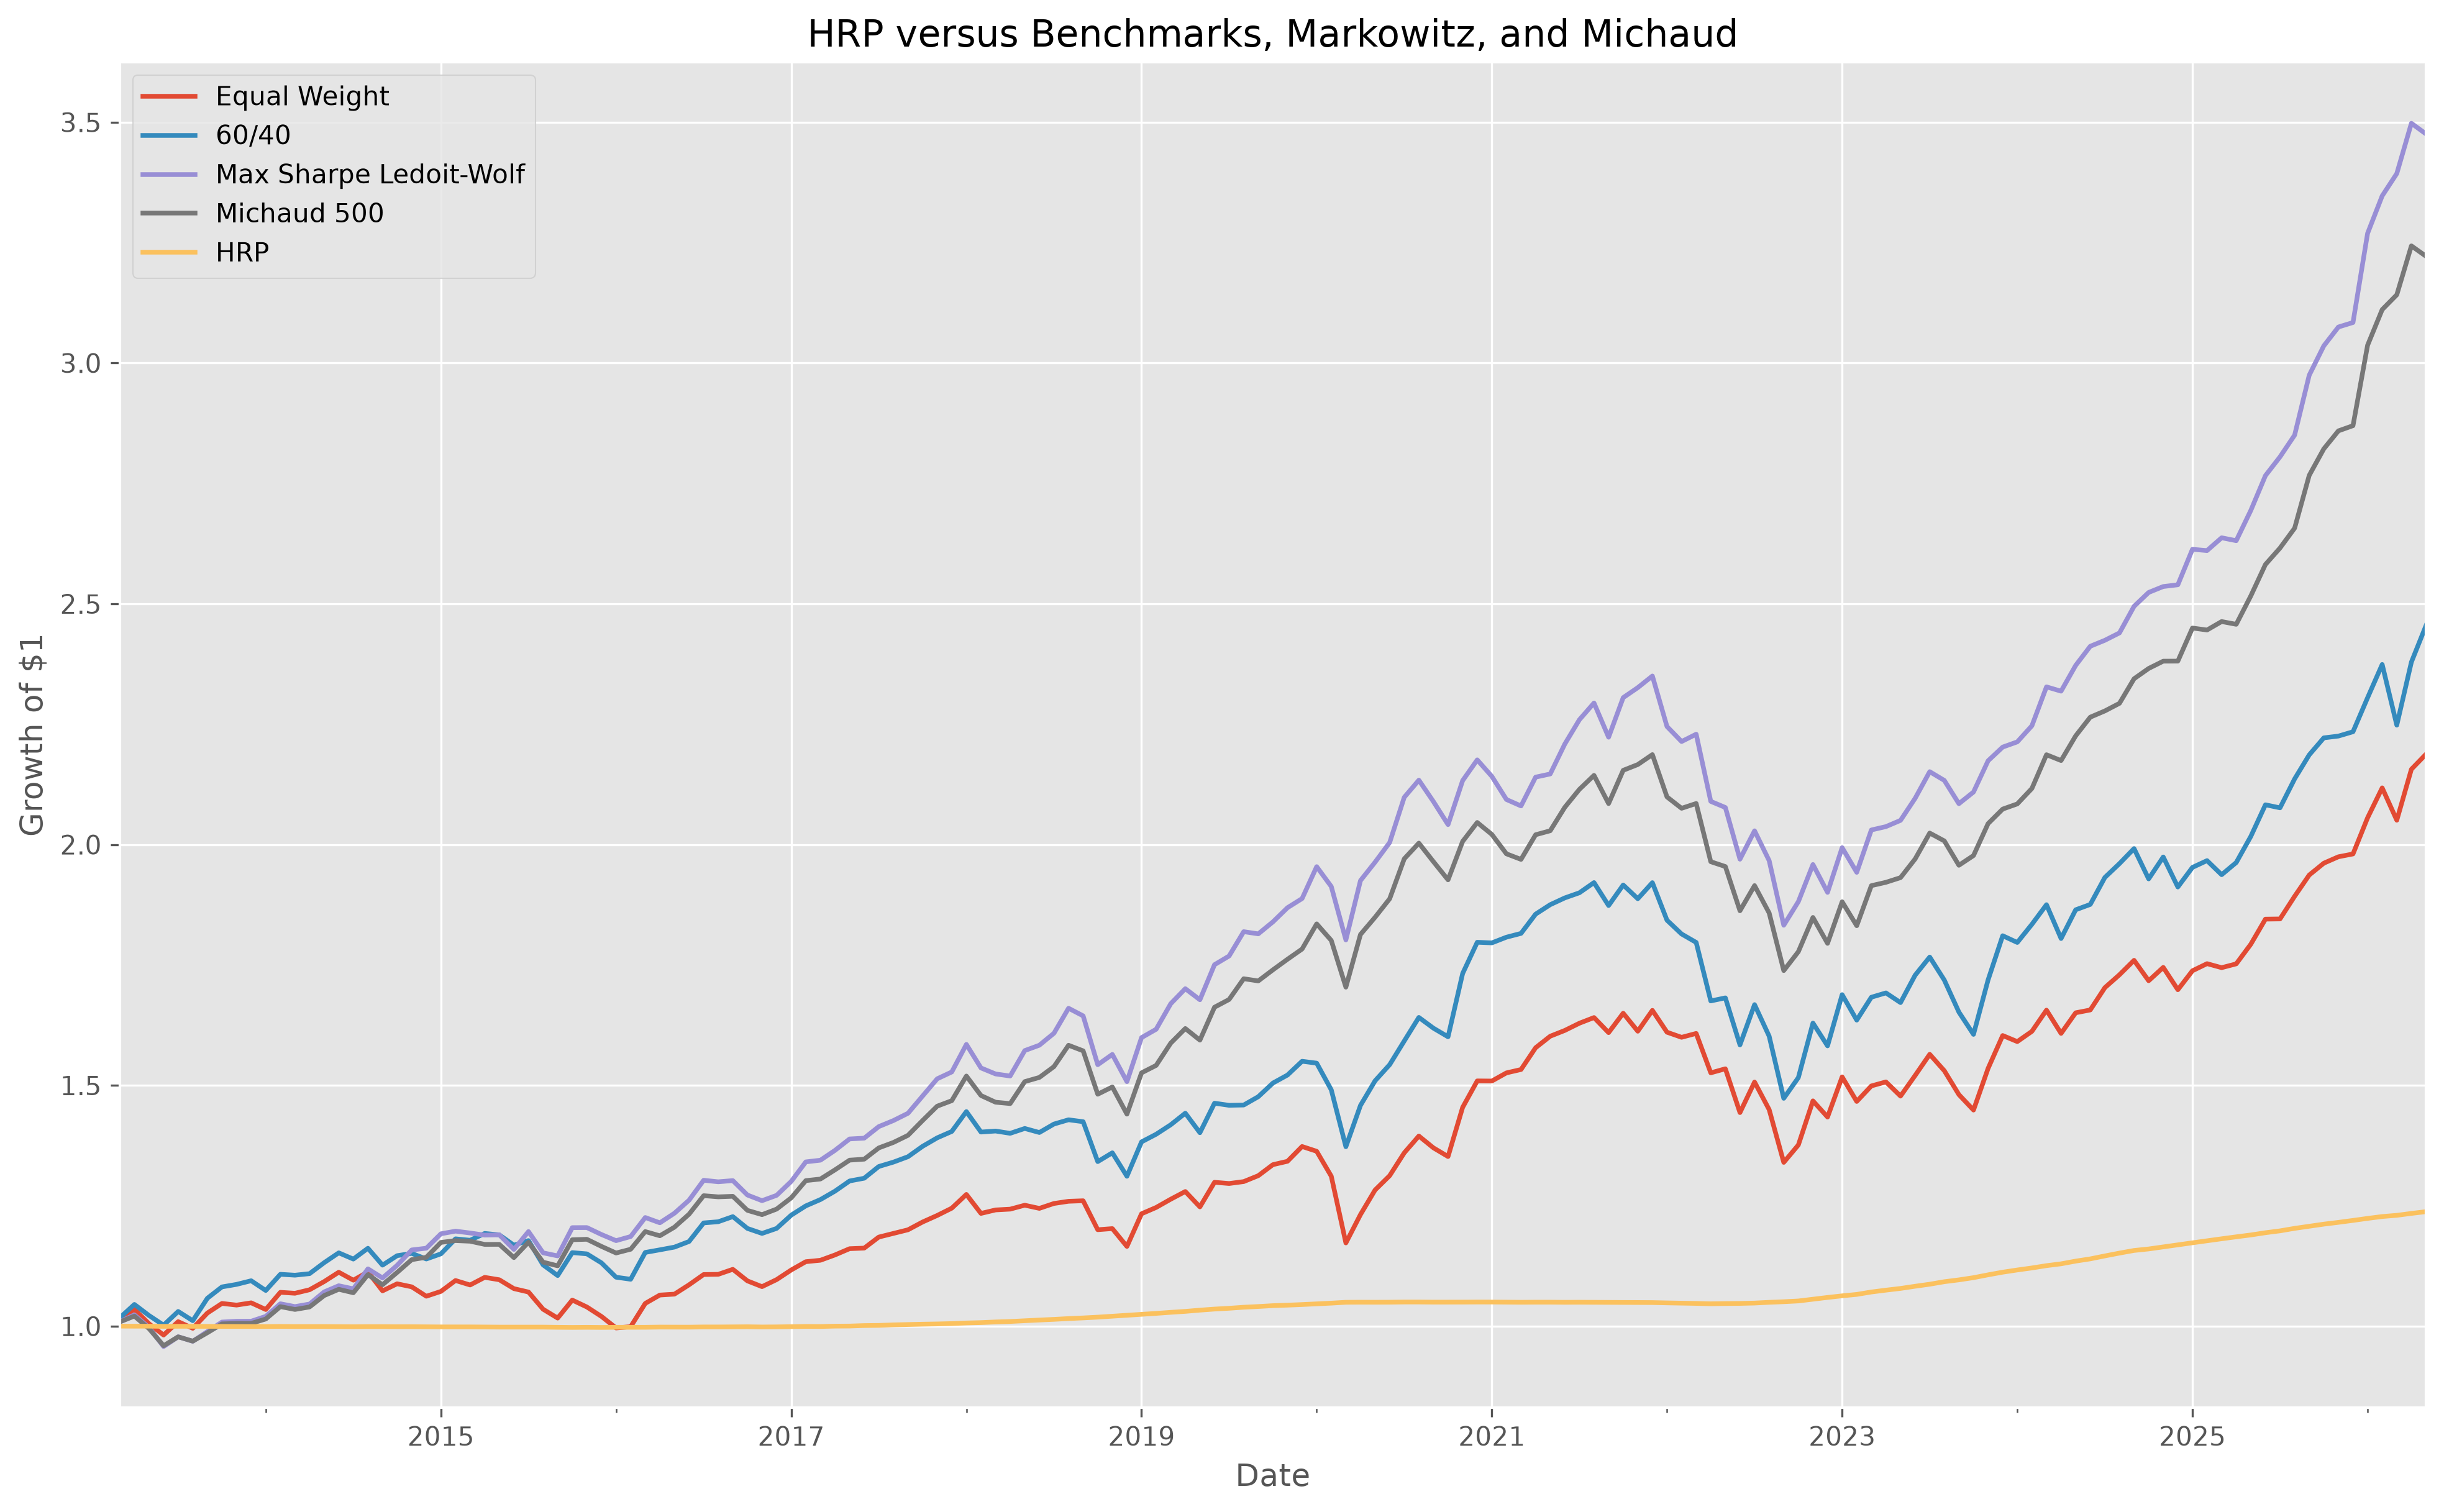

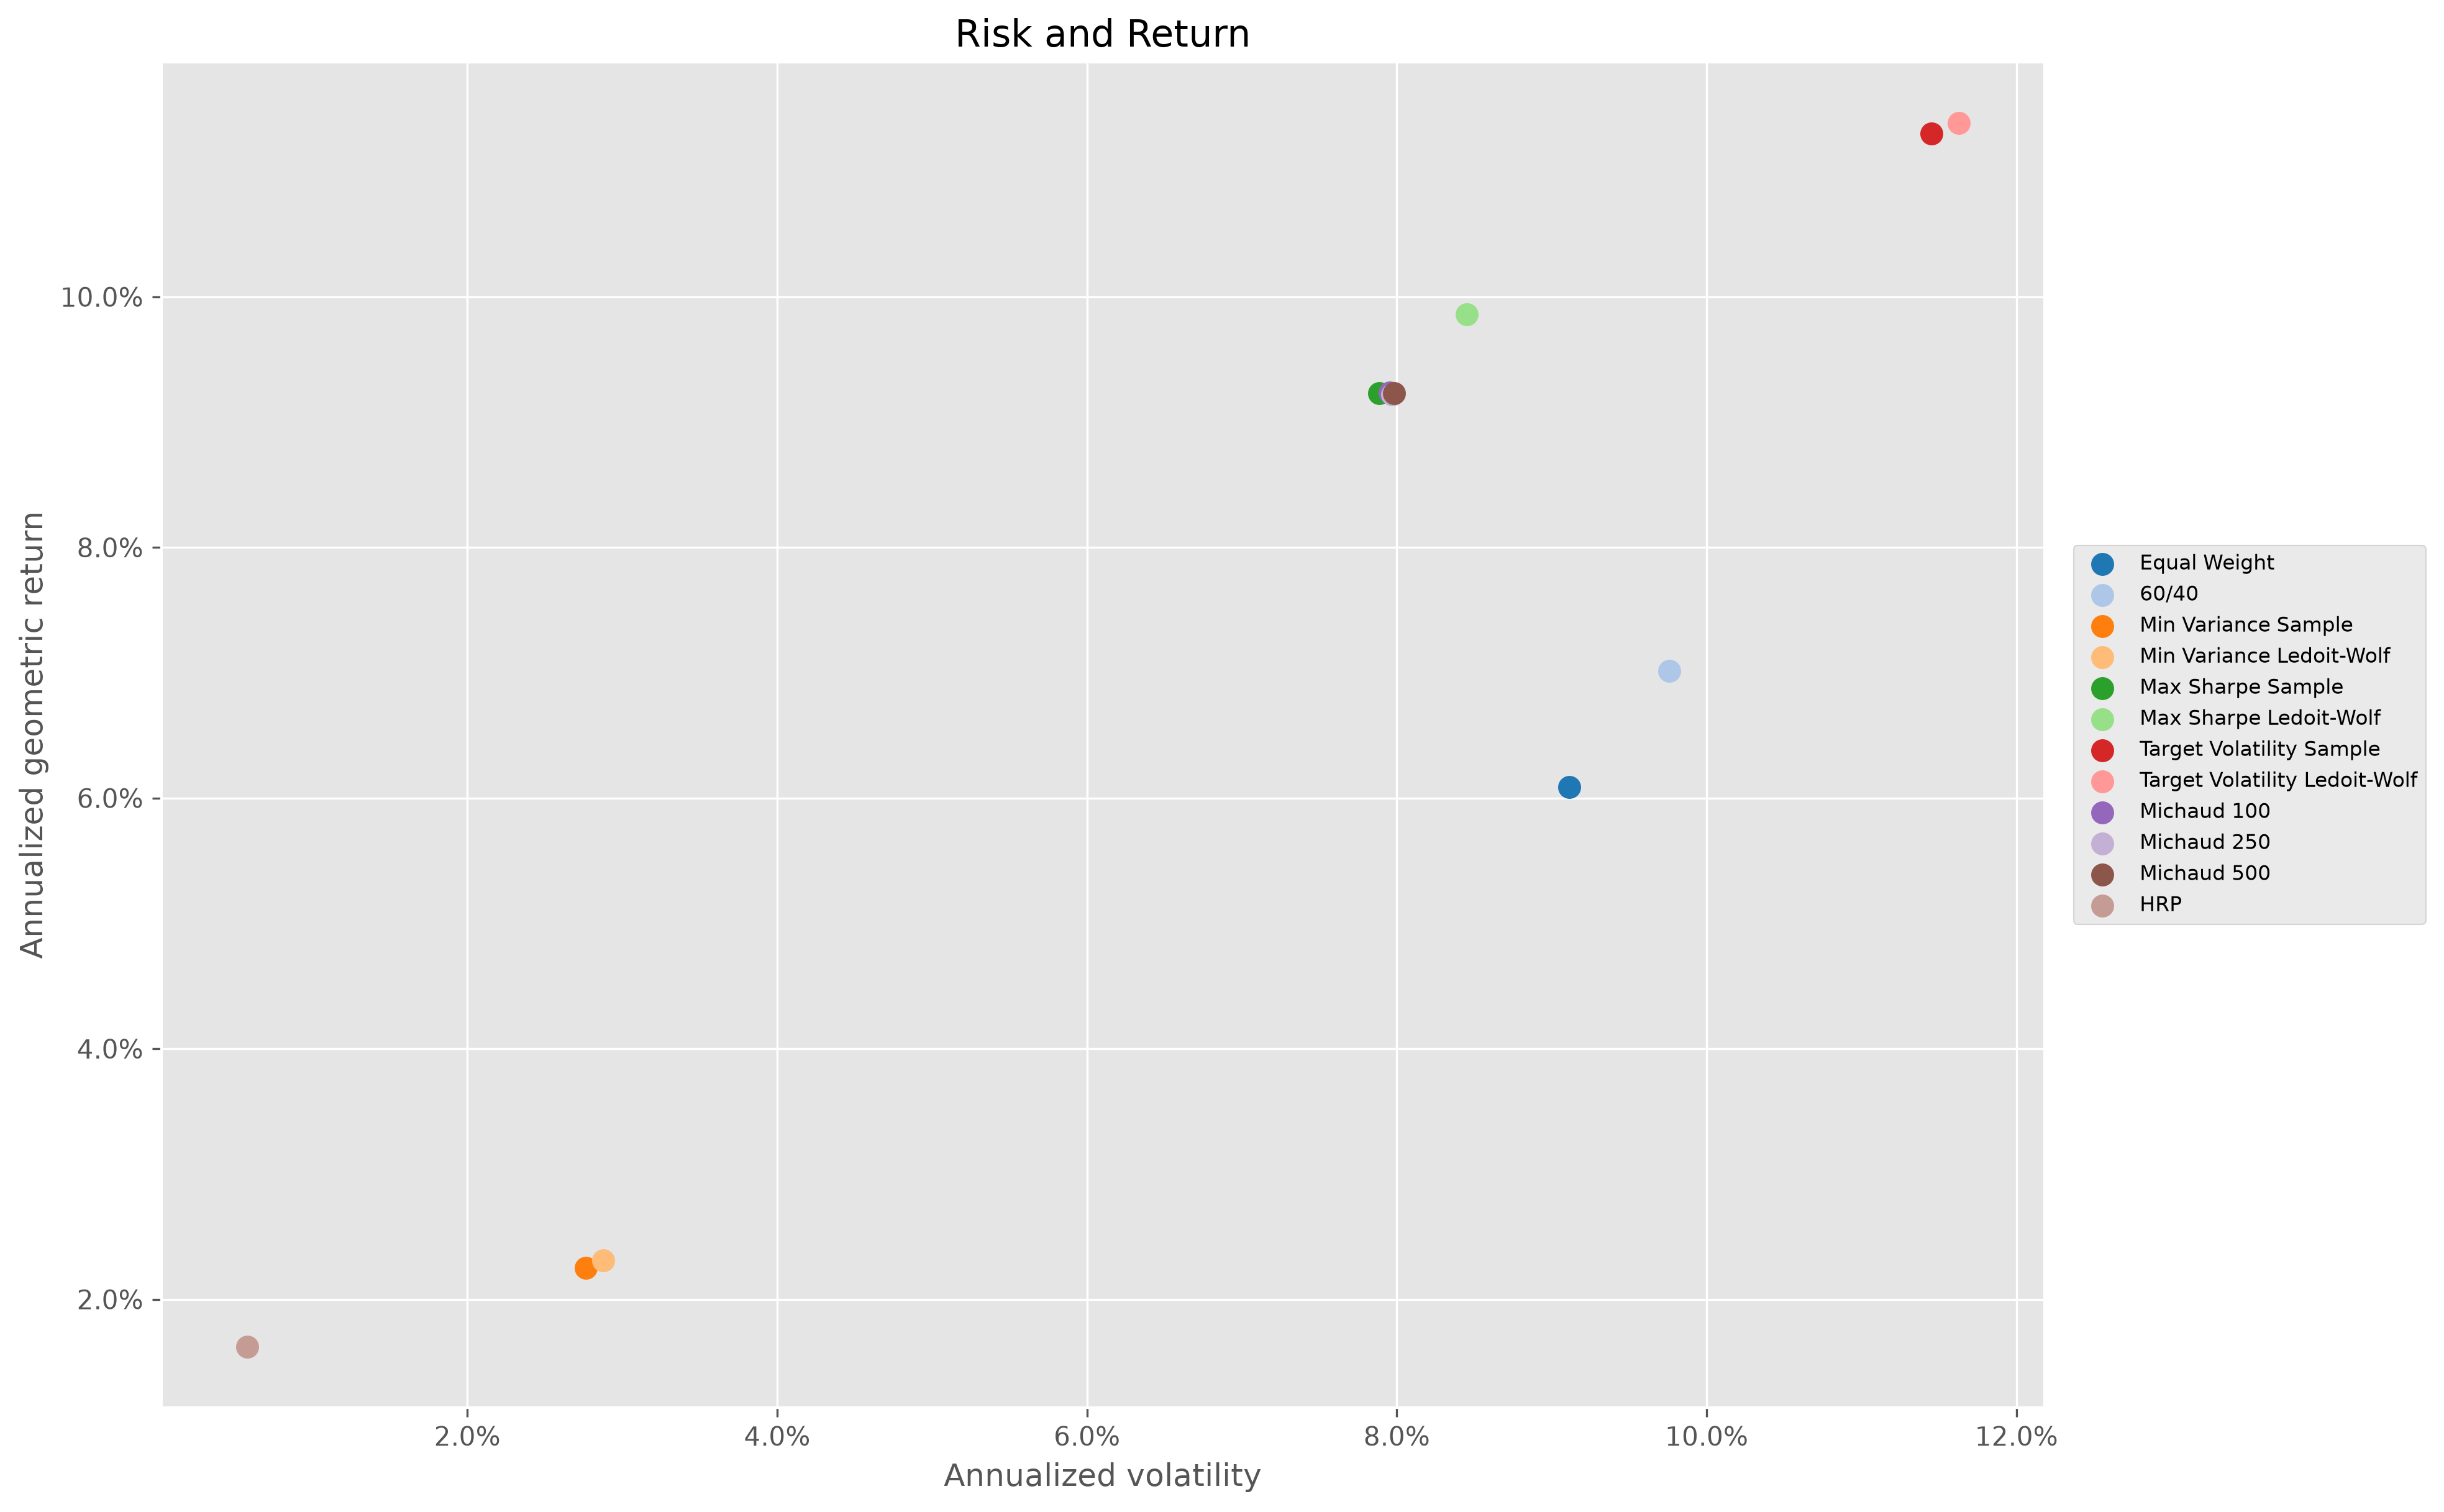

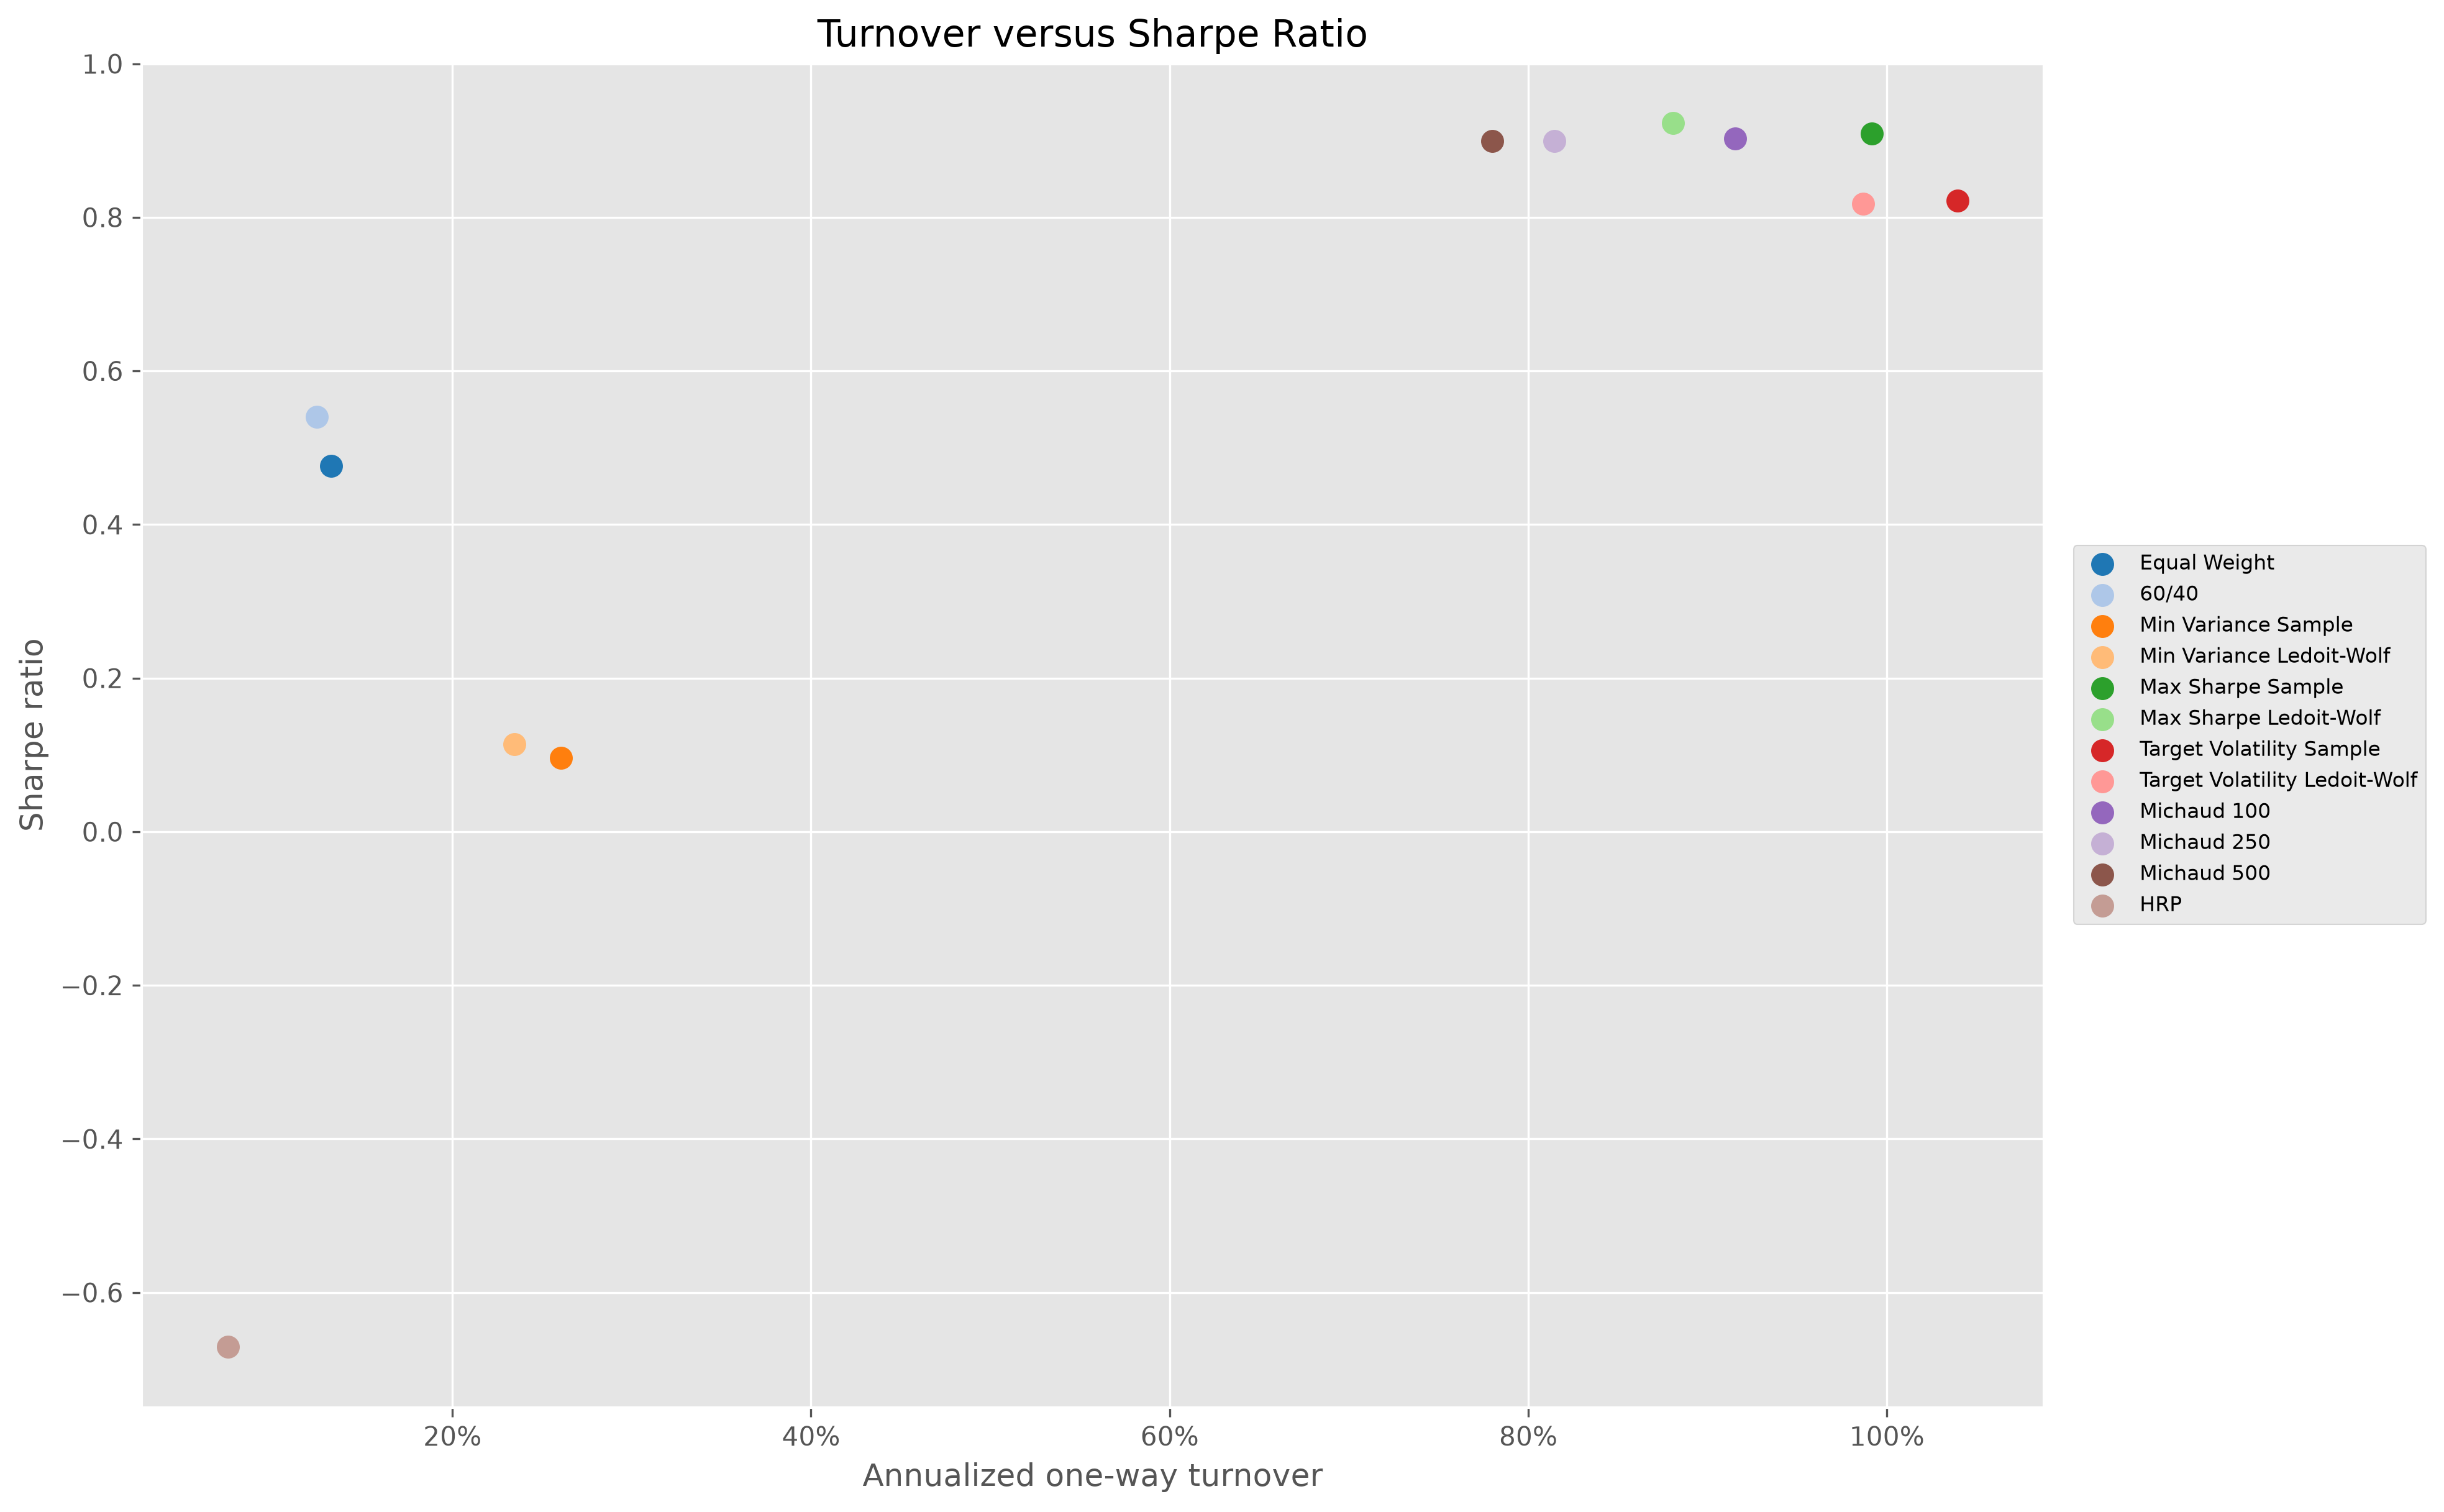

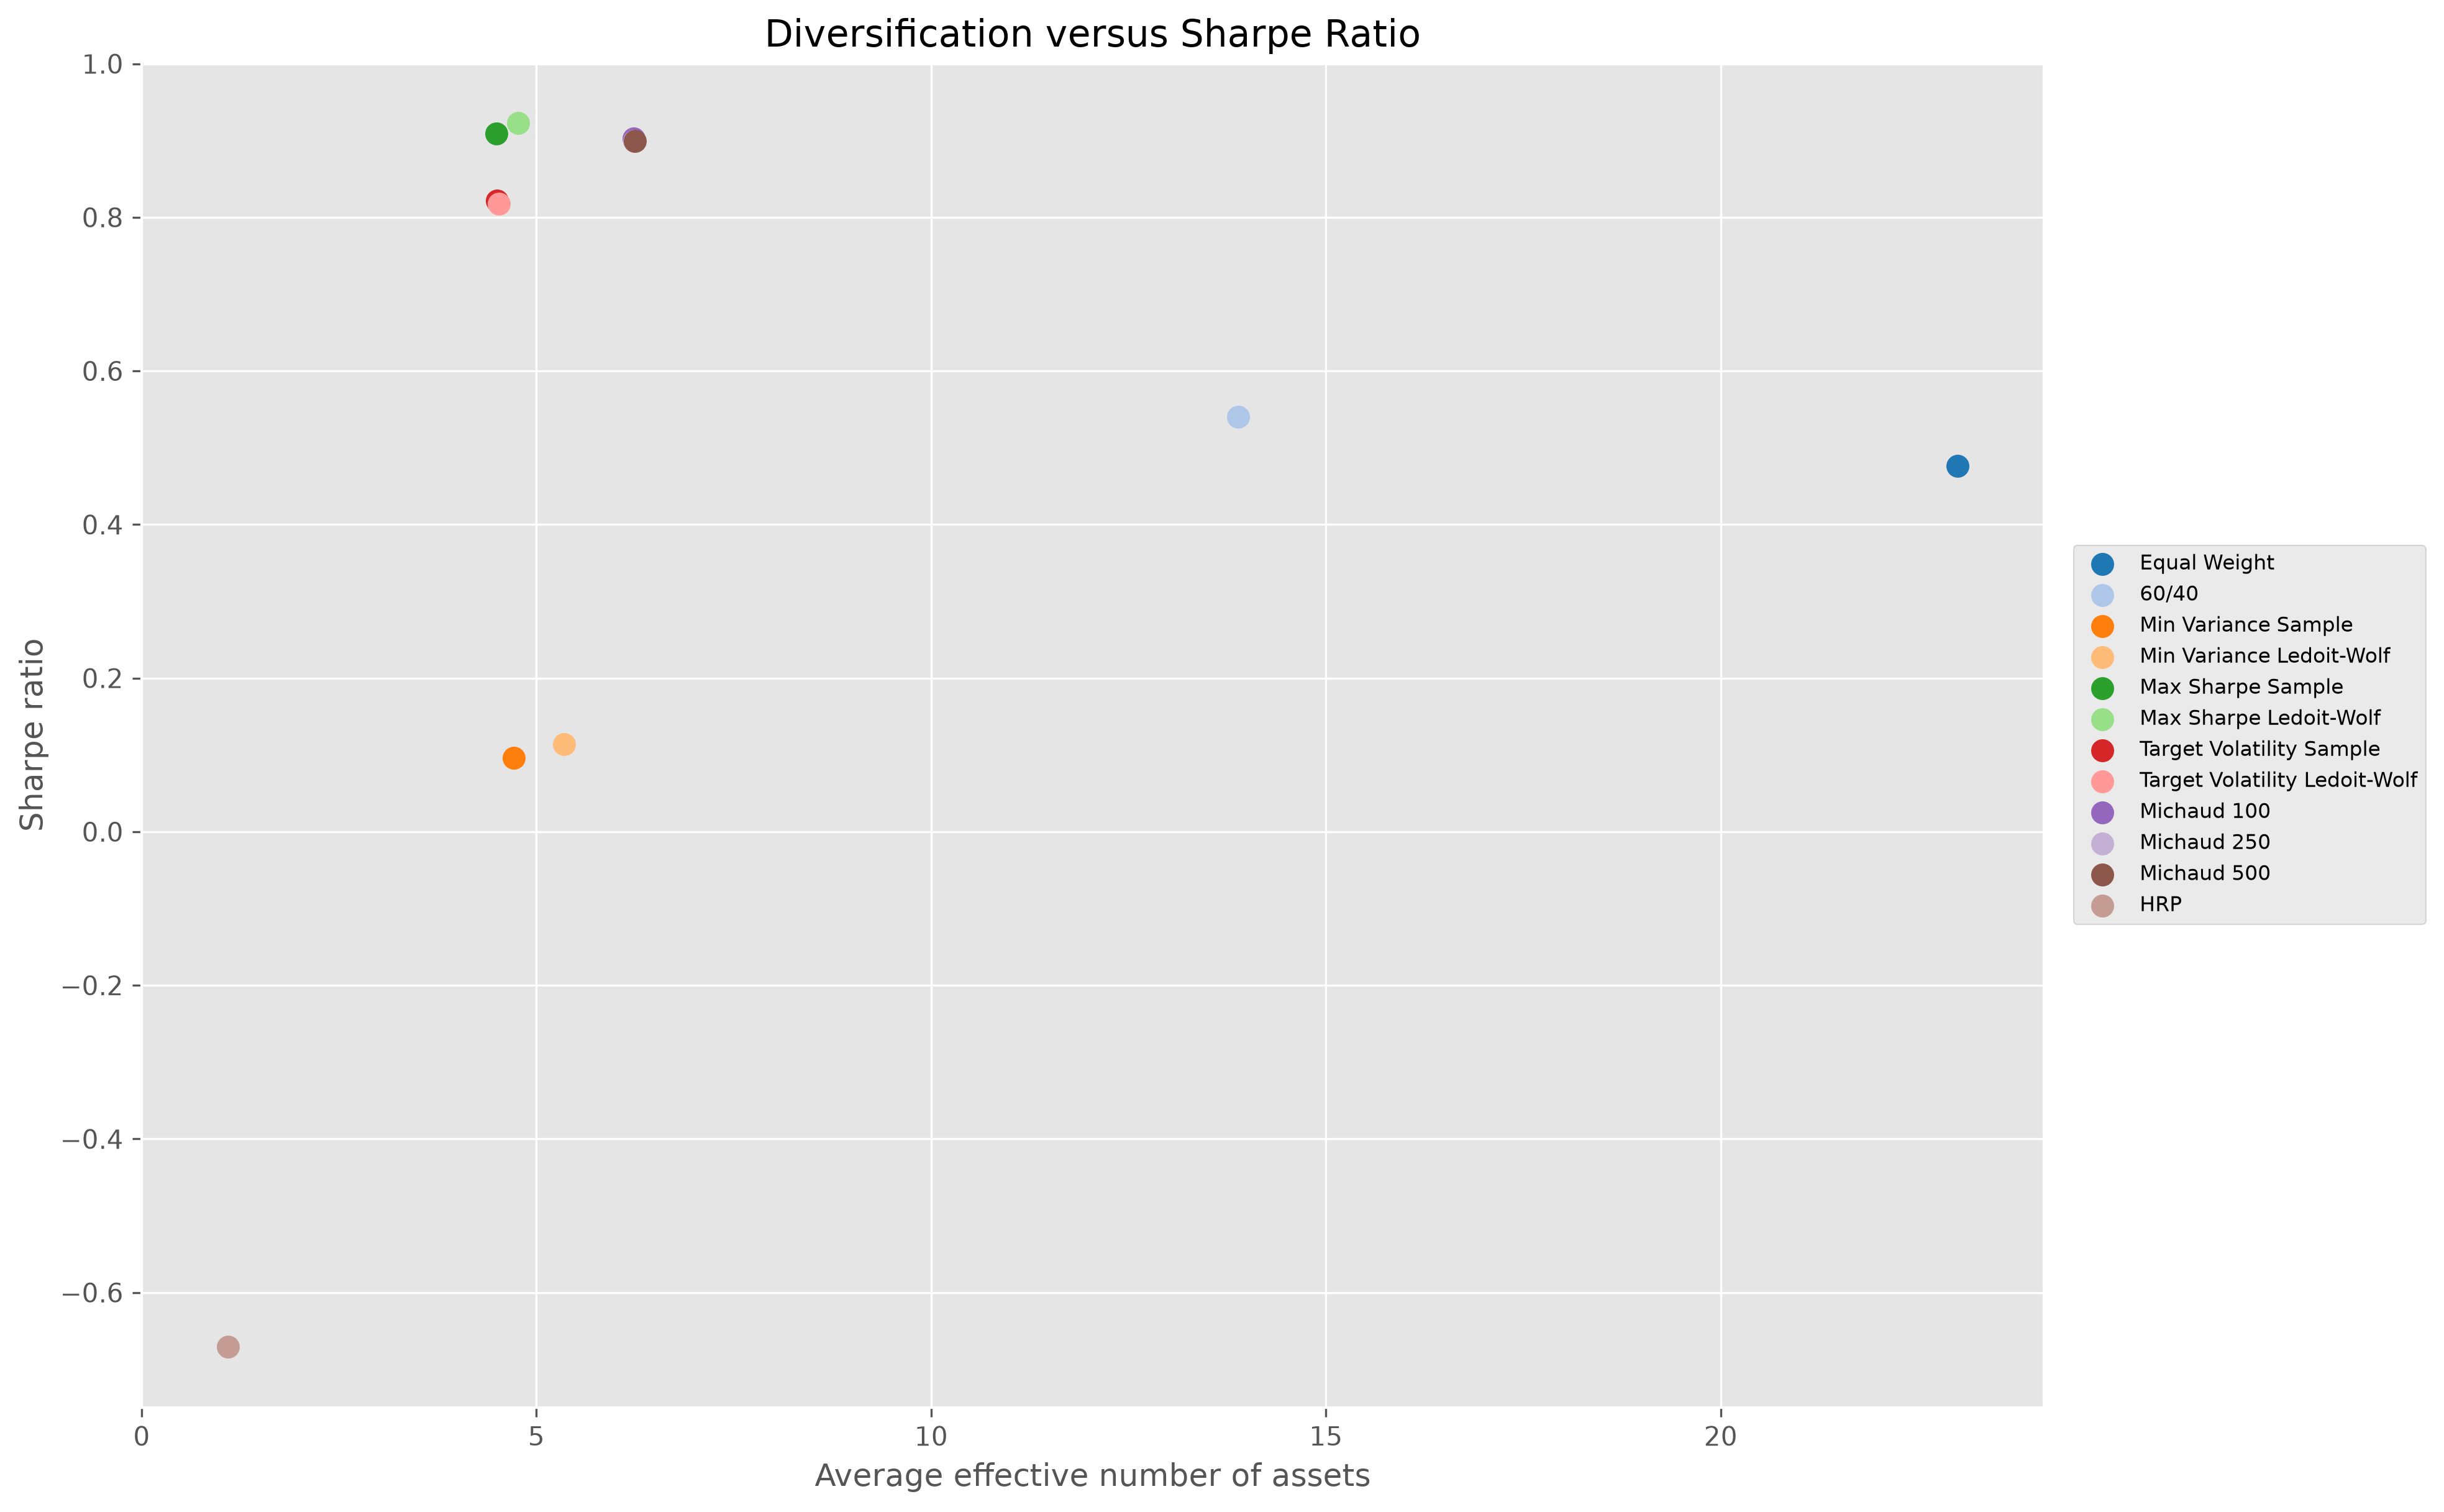

In [3]:
for figure_name in [
    'hrp_weight_heatmap.png',
    'hrp_equity_curve.png',
    'hrp_drawdown.png',
    'hrp_vs_markowitz_vs_michaud.png',
    'risk_return_scatter.png',
    'turnover_vs_sharpe.png',
    'diversification_vs_sharpe.png',
]:
    display(Image(filename=str(PROJECT_ROOT / 'outputs/figures' / figure_name)))